In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [ ]:
ruta = dato("reservas_turisdata.csv")
reservas = pd.read_csv(ruta, parse_dates=["fecha_reserva", "fecha_llegada"])
print(reservas.shape)
reservas.head()

(6000, 18)


,id_reserva,fecha_reserva,fecha_llegada,antelacion_dias,noches,adultos,ninos,tipo_habitacion,regimen,canal,pais_origen,tarifa,deposito,precio_noche,peticiones_especiales,cliente_repetidor,cancelaciones_previas,cancelada
0,5760,2024-01-01,2024-03-21,80,3,3,2,estandar,media_pension,empresa,ES,flexible,parcial,89.24,0,0,0,1
1,3674,2024-01-01,2024-06-06,157,4,1,2,estandar,desayuno,directo,ES,no_reembolsable,sin_deposito,63.50,0,0,0,0
2,1488,2024-01-01,2024-03-19,78,7,2,0,estandar,solo_alojamiento,web_intermediaria,ES,flexible,parcial,94.56,0,0,0,1
3,2259,2024-01-01,2024-03-07,66,7,3,0,familiar,solo_alojamiento,web_intermediaria,ES,no_reembolsable,total,133.22,0,0,0,0
4,2442,2024-01-01,2024-06-23,174,6,2,0,estandar,desayuno,agencia,ES,flexible,parcial,69.80,1,0,0,0


In [ ]:
reservas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id_reserva             6000 non-null   int64         
 1   fecha_reserva          6000 non-null   datetime64[ns]
 2   fecha_llegada          6000 non-null   datetime64[ns]
 3   antelacion_dias        6000 non-null   int64         
 4   noches                 6000 non-null   int64         
 5   adultos                6000 non-null   int64         
 6   ninos                  6000 non-null   int64         
 7   tipo_habitacion        6000 non-null   object        
 8   regimen                6000 non-null   object        
 9   canal                  6000 non-null   object        
 10  pais_origen            5862 non-null   object        
 11  tarifa                 6000 non-null   object        
 12  deposito               6000 non-null   object        
 13  pre

In [ ]:
# Resumen estadístico de las columnas numéricas
reservas.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
id_reserva,6000.0,3000.5,1.0,1500.75,3000.5,4500.25,6000.0,1732.195139
fecha_reserva,6000,2024-12-29 16:58:19.200000,2024-01-01 00:00:00,2024-06-30 00:00:00,2024-12-28 00:00:00,2025-07-02 00:00:00,2025-12-30 00:00:00,NaN
fecha_llegada,6000,2025-03-29 14:25:12,2024-01-13 00:00:00,2024-09-30 18:00:00,2025-03-27 00:00:00,2025-09-28 00:00:00,2026-12-04 00:00:00,NaN
antelacion_dias,6000.0,89.893667,1.0,44.0,75.0,120.0,400.0,62.9854
noches,6000.0,5.522333,1.0,4.0,5.0,7.0,15.0,2.130475
adultos,6000.0,2.201833,1.0,2.0,2.0,2.0,4.0,0.807386
ninos,6000.0,0.496167,0.0,0.0,0.0,1.0,3.0,0.832126
precio_noche,6000.0,102.866493,52.0,77.7425,93.62,118.8125,249.35,34.176982
peticiones_especiales,6000.0,0.582667,0.0,0.0,0.0,1.0,5.0,0.762843
cliente_repetidor,6000.0,0.1485,0.0,0.0,0.0,0.0,1.0,0.355625


In [ ]:
df = pd.read_csv(ruta, parse_dates=["fecha_reserva", "fecha_llegada"])
n_filas, n_columnas = df.shape
assert n_filas == 6000, "Revisa la carga: deberían ser 6000 reservas"
assert n_columnas == 18, "Deberían ser 18 columnas"
assert str(df["fecha_llegada"].dtype).startswith("datetime"), "Parsea las fechas con parse_dates=[...]"

In [ ]:
# Ejemplo: tasa de cancelación por tipo de tarifa
df.groupby("tarifa")["cancelada"].mean().round(3)

,cancelada
tarifa,
flexible,0.519
no_reembolsable,0.367


In [ ]:
# Ejemplo: varias métricas a la vez
df.groupby("canal").agg(reservas=("id_reserva", "count"),
                        precio_medio=("precio_noche", "mean"),
                        tasa_cancelacion=("cancelada", "mean")).round(2)

,reservas,precio_medio,tasa_cancelacion
canal,,,
agencia,1190,103.32,0.44
directo,1462,103.89,0.31
empresa,328,101.53,0.43
web_intermediaria,3020,102.34,0.54


In [ ]:
tasa_por_deposito = df.groupby("deposito")["cancelada"].mean().sort_values(ascending=False)
assert tasa_por_deposito.index[-1] == "total", "Con depósito total debería cancelar menos gente. Revisa el orden"
assert tasa_por_deposito.iloc[0] > tasa_por_deposito.iloc[-1], "Ordena de mayor a menor"

In [ ]:
df["mes_llegada"] = df["fecha_llegada"].dt.month
temporadas = pd.DataFrame({
    "mes_llegada": range(1, 13),
    "temporada": ["alta", "alta", "alta", "baja", "baja", "baja",
                  "alta", "alta", "baja", "baja", "baja", "alta"],
})
temporadas.head(4)

,mes_llegada,temporada
0,1,alta
1,2,alta
2,3,alta
3,4,baja


In [ ]:
df_temp = df.merge(temporadas, on="mes_llegada", how="left")
tasa_por_temporada = df_temp.groupby("temporada")["cancelada"].mean()
assert len(df_temp) == len(df), "Un merge 'left' con clave única no debe cambiar el número de filas"
assert "temporada" in df_temp.columns, "Falta la columna temporada"
assert set(tasa_por_temporada.index) == {"alta", "baja"}

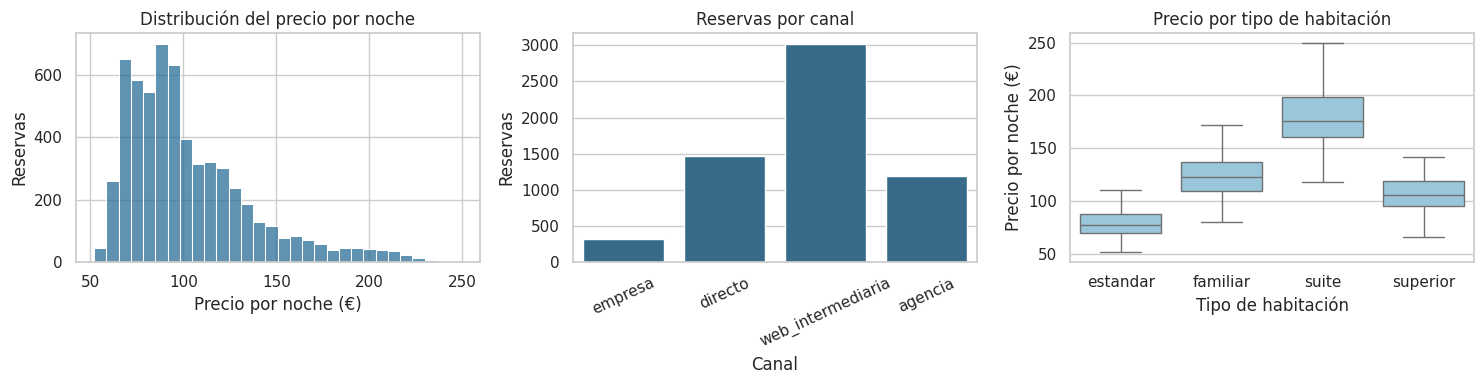

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["precio_noche"], bins=30, ax=ejes[0], color="#2a6f97")
ejes[0].set(title="Distribución del precio por noche", xlabel="Precio por noche (€)", ylabel="Reservas")
sns.countplot(data=df, x="canal", ax=ejes[1], color="#2a6f97")
ejes[1].set(title="Reservas por canal", xlabel="Canal", ylabel="Reservas")
ejes[1].tick_params(axis="x", rotation=25)
sns.boxplot(data=df, x="tipo_habitacion", y="precio_noche", ax=ejes[2], color="#8ecae6")
ejes[2].set(title="Precio por tipo de habitación", xlabel="Tipo de habitación", ylabel="Precio por noche (€)")
plt.tight_layout()
plt.show()

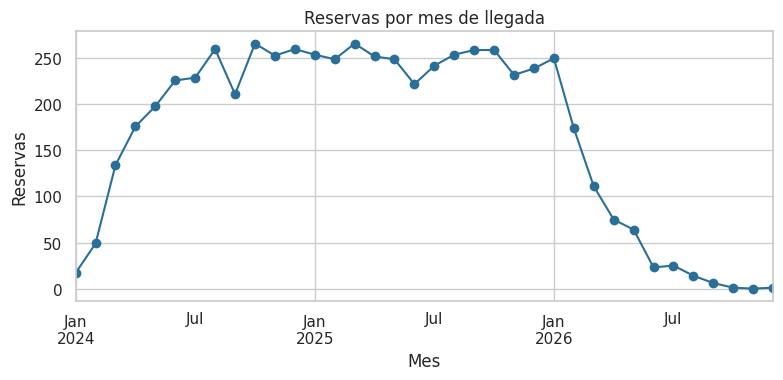

In [ ]:
# Serie temporal: reservas por mes de llegada
por_mes = df.set_index("fecha_llegada").resample("MS")["id_reserva"].count()
plt.figure(figsize=(9, 3.5))
por_mes.plot(marker="o", color="#2a6f97")
plt.title("Reservas por mes de llegada")
plt.xlabel("Mes")
plt.ylabel("Reservas")
plt.show()

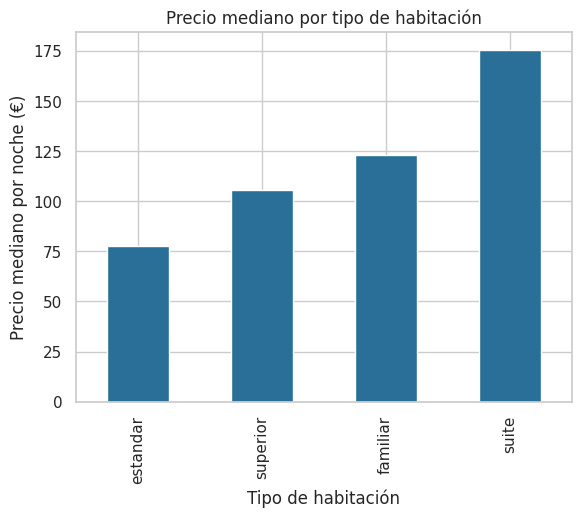

In [ ]:
mediana_por_tipo = df.groupby("tipo_habitacion")["precio_noche"].median().sort_values()
mediana_por_tipo.plot(kind="bar", color="#2a6f97")
plt.title("Precio mediano por tipo de habitación")
plt.xlabel("Tipo de habitación")
plt.ylabel("Precio mediano por noche (€)")
plt.show()
tipo_mas_caro = mediana_por_tipo.idxmax()
assert tipo_mas_caro == "suite", "Revisa: el tipo con mayor mediana de precio debería ser la suite"
assert len(mediana_por_tipo) == 4, "Debe haber 4 tipos de habitación"

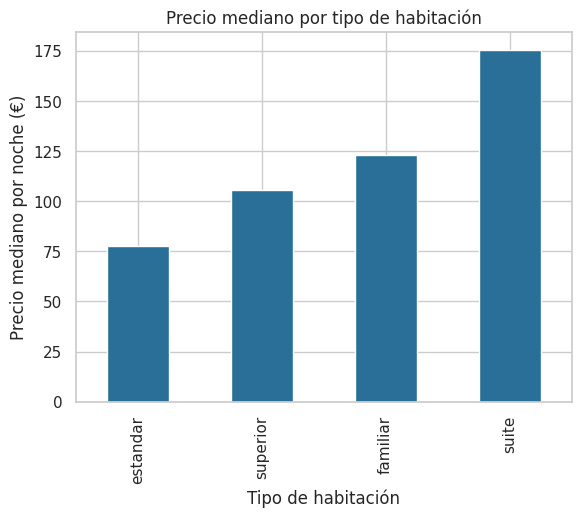

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
mediana_por_tipo = df.groupby("tipo_habitacion")["precio_noche"].median().sort_values()
mediana_por_tipo.plot(kind="bar", color="#2a6f97")
plt.title("Precio mediano por tipo de habitación")
plt.xlabel("Tipo de habitación")
plt.ylabel("Precio mediano por noche (€)")
plt.show()
tipo_mas_caro = mediana_por_tipo.idxmax()
assert tipo_mas_caro == "suite", "Revisa: el tipo con mayor mediana de precio debería ser la suite"
assert len(mediana_por_tipo) == 4, "Debe haber 4 tipos de habitación"

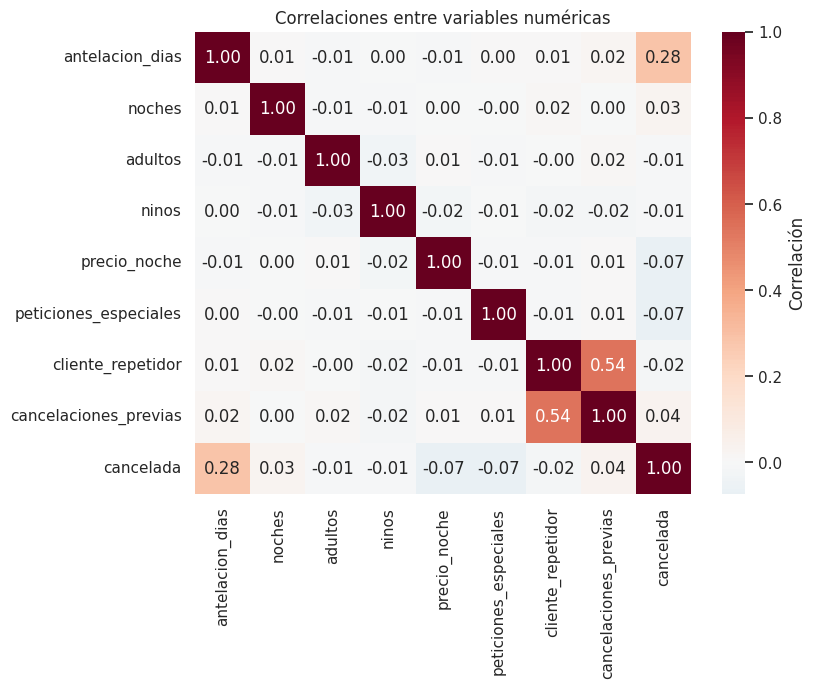

In [ ]:
numericas = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
             "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "cancelada"]
corr = df[numericas].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "Correlación"})
plt.title("Correlaciones entre variables numéricas")
plt.show()

In [ ]:
var_mas_ligada = corr["cancelada"].drop("cancelada").abs().idxmax()
assert isinstance(var_mas_ligada, str) and var_mas_ligada != "cancelada", "Debe ser otra variable"
assert var_mas_ligada in numericas, "Debe ser una de las variables de la matriz"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
var_mas_ligada = corr["cancelada"].drop("cancelada").abs().idxmax()
assert isinstance(var_mas_ligada, str) and var_mas_ligada != "cancelada", "Debe ser el nombre de otra variable"
assert var_mas_ligada in numericas, "Debe ser una de las variables de la matriz"

In [ ]:
def resumen_calidad(tabla):
    """Devuelve una tabla con el estado de calidad de cada columna."""
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "distintos": tabla.nunique(),
    })

resumen_calidad(df)

,tipo,nulos,pct_nulos,distintos
id_reserva,int64,0,0.0,6000
fecha_reserva,datetime64[ns],0,0.0,728
fecha_llegada,datetime64[ns],0,0.0,897
antelacion_dias,int64,0,0.0,327
noches,int64,0,0.0,15
adultos,int64,0,0.0,4
ninos,int64,0,0.0,4
tipo_habitacion,object,0,0.0,4
regimen,object,0,0.0,4
canal,object,0,0.0,4


In [ ]:
filas_duplicadas = df.duplicated().sum()
pct_nulos_pais = round(df["pais_origen"].isna().mean() * 100, 1)
assert filas_duplicadas == 0, "Esta tabla limpia no debería tener duplicados"
assert 1.0 <= pct_nulos_pais <= 3.0, "El porcentaje de nulos de pais_origen debería rondar el 2 %"

In [ ]:
tasa_dep = df.groupby("deposito")["cancelada"].mean() * 100
tasa_canal = df.groupby("canal")["cancelada"].mean() * 100
precio_hab = df.groupby("tipo_habitacion")["precio_noche"].median()

hallazgos = [
    f"Con depósito total cancela el {tasa_dep['total']:.1f} % de las reservas, frente al {tasa_dep.max():.1f} % de la modalidad con mayor cancelación ({tasa_dep.idxmax()}).",
    f"El canal con más cancelaciones es '{tasa_canal.idxmax()}' ({tasa_canal.max():.1f} %) y el que menos '{tasa_canal.idxmin()}' ({tasa_canal.min():.1f} %).",
    f"La suite tiene un precio mediano de {precio_hab['suite']:.0f} € por noche, el más alto de los {len(precio_hab)} tipos de habitación.",
]
for h in hallazgos:
    print("-", h)
assert len(hallazgos) >= 3, "Escribe al menos tres hallazgos"
assert all(isinstance(h, str) and any(c.isdigit() for c in h) for h in hallazgos), "Cada hallazgo debe ser texto e incluir una cifra"

- Con depósito total cancela el 26.4 % de las reservas, frente al 54.0 % de la modalidad con mayor cancelación (sin_deposito).
- El canal con más cancelaciones es 'web_intermediaria' (53.9 %) y el que menos 'directo' (31.5 %).
- La suite tiene un precio mediano de 175 € por noche, el más alto de los 4 tipos de habitación.


In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
sns.set_theme(style="whitegrid")

In [ ]:
crudo = pd.read_csv(dato("reservas_sucio.csv"))
print(crudo.shape)
crudo.info()

(1545, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1545 entries, 0 to 1544
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_reserva             1545 non-null   int64  
 1   fecha_reserva          1545 non-null   object 
 2   fecha_llegada          1545 non-null   object 
 3   antelacion_dias        1545 non-null   int64  
 4   noches                 1545 non-null   int64  
 5   adultos                1499 non-null   float64
 6   ninos                  1545 non-null   int64  
 7   tipo_habitacion        1545 non-null   object 
 8   regimen                1484 non-null   object 
 9   canal                  1545 non-null   object 
 10  pais_origen            1430 non-null   object 
 11  tarifa                 1545 non-null   object 
 12  deposito               1545 non-null   object 
 13  precio_noche           1461 non-null   object 
 14  peticiones_especiales  1545 non-null   int64 

In [ ]:
def resumen_calidad(tabla):
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "distintos": tabla.nunique(),
    })

resumen_calidad(crudo)

,tipo,nulos,pct_nulos,distintos
id_reserva,int64,0,0.00,1500
fecha_reserva,object,0,0.00,753
fecha_llegada,object,0,0.00,677
antelacion_dias,int64,0,0.00,264
noches,int64,0,0.00,17
adultos,float64,46,2.98,4
ninos,int64,0,0.00,4
tipo_habitacion,object,0,0.00,4
regimen,object,61,3.95,4
canal,object,0,0.00,9


In [ ]:
print("Filas duplicadas exactas:", crudo.duplicated().sum())
crudo[crudo.duplicated(keep=False)].sort_values("id_reserva").head(6)

Filas duplicadas exactas: 45


,id_reserva,fecha_reserva,fecha_llegada,antelacion_dias,noches,adultos,ninos,tipo_habitacion,regimen,canal,pais_origen,tarifa,deposito,precio_noche,peticiones_especiales,cliente_repetidor,cancelaciones_previas,cancelada
405,192,2025-04-05,2025-05-17,42,5,2.0,0,superior,todo_incluido,web_intermediaria,UK,flexible,sin_deposito,"83,36",3,0,0,1
837,192,2025-04-05,2025-05-17,42,5,2.0,0,superior,todo_incluido,web_intermediaria,UK,flexible,sin_deposito,"83,36",3,0,0,1
1467,359,2024-03-07,2024-07-10,125,8,2.0,0,estandar,media_pension,web_intermediaria,España,flexible,sin_deposito,86.05,0,0,0,1
1401,359,2024-03-07,2024-07-10,125,8,2.0,0,estandar,media_pension,web_intermediaria,España,flexible,sin_deposito,86.05,0,0,0,1
878,511,27/12/2025,2026-04-15,109,5,2.0,0,familiar,desayuno,web_intermediaria,UK,no_reembolsable,parcial,"122,55",1,0,0,0
1277,511,27/12/2025,2026-04-15,109,5,2.0,0,familiar,desayuno,web_intermediaria,UK,no_reembolsable,parcial,"122,55",1,0,0,0


In [ ]:
n_duplicados = crudo.duplicated().sum()
d1 = crudo.drop_duplicates().reset_index(drop=True)
assert n_duplicados == 45, "Cuenta las filas duplicadas con crudo.duplicated().sum()"
assert len(d1) == 1500, "Tras quitar duplicados deben quedar 1500 reservas"
assert d1["id_reserva"].is_unique, "id_reserva debería ser único tras deduplicar"

In [ ]:
con_coma = d1["precio_noche"].astype(str).str.contains(",").sum()
print("Precios con coma decimal:", con_coma)

Precios con coma decimal: 147


In [ ]:
d2 = d1.copy()
d2["precio_noche"] = pd.to_numeric(
    d2["precio_noche"].astype(str).str.replace(",", "."), errors="coerce"
)
nulos_precio = d2["precio_noche"].isna().sum()
assert d2["precio_noche"].dtype == float, "precio_noche debe ser float"
assert 60 <= nulos_precio <= 90, "Los nulos de precio deberían ser los ya existentes (unos 5 %); si salen muchos más, revisa la conversión"

In [ ]:
iso = pd.to_datetime(d2["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
espanol = pd.to_datetime(d2["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
print("ISO:", iso.notna().sum(), "· dd/mm/aaaa:", espanol.notna().sum(), "· sin leer:", (iso.isna() & espanol.isna()).sum())

ISO: 1350 · dd/mm/aaaa: 150 · sin leer: 0


In [ ]:
d3 = d2.copy()
d3["fecha_reserva"] = iso.fillna(espanol)
d3["fecha_llegada"] = pd.to_datetime(d3["fecha_llegada"])
assert str(d3["fecha_reserva"].dtype).startswith("datetime"), "fecha_reserva debe ser datetime"
assert d3["fecha_reserva"].isna().sum() == 0, "No debe quedar ninguna fecha sin leer"
assert d3["fecha_reserva"].min().year == 2024, "Comprueba que no has intercambiado día y mes"

In [ ]:
print(d3["canal"].value_counts().to_string())
print()
print(d3["pais_origen"].value_counts().to_string())

canal
web_intermediaria     699
directo               297
agencia               289
empresa                80
WEB_INTERMEDIARIA      34
Web Intermediaria      33
web intermediaria      28
Directo                24
directo                16

pais_origen
ES             341
UK             307
DE             219
otros          139
Nordicos        85
IT              77
NL              75
FR              56
España          24
es              23
Reino Unido     22
uk              20


In [ ]:
equivalencias = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
                 "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}
d4 = d3.copy()
d4["canal"] = d4["canal"].str.strip().str.lower().str.replace(" ", "_")
d4["pais_origen"] = d4["pais_origen"].str.strip().str.lower().map(equivalencias)
assert sorted(d4["canal"].unique()) == ["agencia", "directo", "empresa", "web_intermediaria"], "Canal: deben quedar 4 valores"
assert d4["pais_origen"].nunique() == 8, "País: deben quedar 8 valores (los nulos no cuentan)"
assert d4["pais_origen"].isna().sum() == d3["pais_origen"].isna().sum(), "El mapeo no debe crear nulos nuevos: revisa el diccionario"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
equivalencias = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
                 "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}
d4 = d3.copy()
d4["canal"] = d4["canal"].str.strip().str.lower().str.replace(" ", "_")
d4["pais_origen"] = d4["pais_origen"].str.strip().str.lower().map(equivalencias)
assert sorted(d4["canal"].unique()) == ["agencia", "directo", "empresa", "web_intermediaria"], "Canal: deben quedar 4 valores"
assert d4["pais_origen"].nunique() == 8, "País: deben quedar 8 valores (los nulos no cuentan)"
assert d4["pais_origen"].isna().sum() == d3["pais_origen"].isna().sum(), "El mapeo no debe crear nulos nuevos: revisa el diccionario"

       precio_noche  noches  antelacion_dias
count        1421.0  1500.0           1500.0
mean          130.2     5.5             88.6
std           525.6     2.1             62.3
min           -50.0    -2.0             -3.0
25%            77.9     4.0             42.0
50%            93.2     5.0             75.0
75%           119.7     7.0            121.0
max          9999.0    15.0            400.0


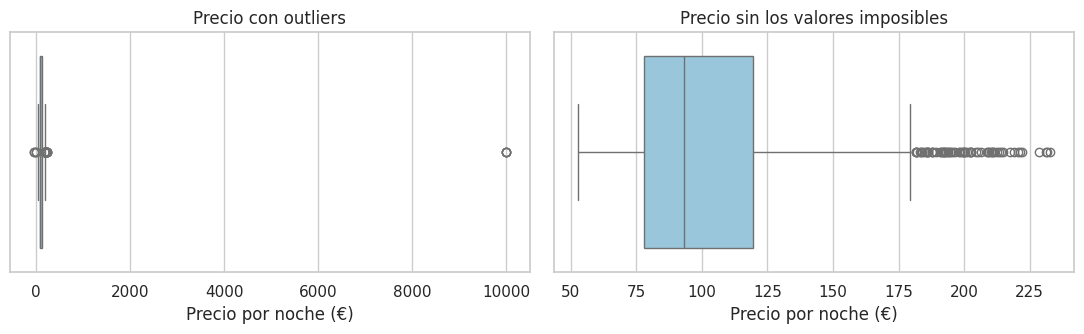

In [ ]:
print(d4[["precio_noche", "noches", "antelacion_dias"]].describe().round(1))
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=d4["precio_noche"], ax=ejes[0], color="#8ecae6")
ejes[0].set(title="Precio con outliers", xlabel="Precio por noche (€)")
sns.boxplot(x=d4.loc[d4["precio_noche"].between(1, 1000), "precio_noche"], ax=ejes[1], color="#8ecae6")
ejes[1].set(title="Precio sin los valores imposibles", xlabel="Precio por noche (€)")
plt.tight_layout()
plt.show()

In [ ]:
d5 = d4.copy()
nulos_antes = d5[["precio_noche", "noches"]].isna().sum().sum()
d5["precio_noche"] = d5["precio_noche"].where(d5["precio_noche"].between(20, 1000))
d5["noches"] = d5["noches"].where(d5["noches"].between(1, 60))
n_imposibles = d5[["precio_noche", "noches"]].isna().sum().sum() - nulos_antes
assert d5["precio_noche"].dropna().between(20, 1000).all(), "Quedan precios fuera de rango"
assert (d5["noches"].dropna() >= 1).all(), "Quedan noches <= 0"
assert 8 <= n_imposibles <= 14, "Deberían ser unos 10-14 valores imposibles (precios y noches). Revisa las reglas"

In [ ]:
antelacion_calculada = (d5["fecha_llegada"] - d5["fecha_reserva"]).dt.days
incoherentes = antelacion_calculada != d5["antelacion_dias"]
print("Antelaciones negativas:", (d5["antelacion_dias"] < 0).sum())
print("Antelaciones que no cuadran con las fechas:", incoherentes.sum())
# Las fechas mandan: recalculamos toda la columna desde ellas
d5["antelacion_dias"] = antelacion_calculada
print("Mínimo tras recalcular:", d5["antelacion_dias"].min())

Antelaciones negativas: 5
Antelaciones que no cuadran con las fechas: 5
Mínimo tras recalcular: 1


In [ ]:
resumen_calidad(d5).query("nulos > 0")

,tipo,nulos,pct_nulos,distintos
noches,float64,6,0.40,15
adultos,float64,46,3.07,4
regimen,object,59,3.93,4
pais_origen,object,112,7.47,8
precio_noche,float64,87,5.80,1321


In [ ]:
EQUIV_PAIS = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
              "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}

def limpiar_reservas(tabla):
    t = tabla.copy()
    resumen = {"filas_antes": len(t)}
    t = t.drop_duplicates().reset_index(drop=True)
    resumen["duplicados_quitados"] = resumen["filas_antes"] - len(t)
    t["precio_noche"] = pd.to_numeric(t["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")
    iso = pd.to_datetime(t["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
    esp = pd.to_datetime(t["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
    t["fecha_reserva"] = iso.fillna(esp)
    t["fecha_llegada"] = pd.to_datetime(t["fecha_llegada"], format="%Y-%m-%d")
    t["canal"] = t["canal"].str.strip().str.lower().str.replace(" ", "_")
    t["pais_origen"] = t["pais_origen"].str.strip().str.lower().map(EQUIV_PAIS)
    nulos_antes = t[["precio_noche", "noches"]].isna().sum().sum()
    t["precio_noche"] = t["precio_noche"].where(t["precio_noche"].between(20, 1000))
    t["noches"] = t["noches"].where(t["noches"].between(1, 60))
    resumen["imposibles_a_nulo"] = int(t[["precio_noche", "noches"]].isna().sum().sum() - nulos_antes)
    antes = t["antelacion_dias"]
    t["antelacion_dias"] = (t["fecha_llegada"] - t["fecha_reserva"]).dt.days
    resumen["antelaciones_recalculadas"] = int((t["antelacion_dias"] != antes).sum())
    resumen["filas_despues"] = len(t)
    return t, resumen

limpio, resumen = limpiar_reservas(crudo)
print(resumen)
assert len(crudo) == 1545, "La función no debe modificar el DataFrame original"
assert limpio.shape[0] == 1500, "Deben quedar 1500 filas"
assert limpio["id_reserva"].is_unique
assert limpio["canal"].nunique() == 4 and limpio["pais_origen"].nunique() == 8
assert limpio["precio_noche"].dtype == float
assert (limpio["antelacion_dias"] >= 0).all() and (limpio["noches"].dropna() > 0).all()
assert str(limpio["fecha_reserva"].dtype).startswith("datetime")
assert resumen["filas_antes"] == 1545 and resumen["duplicados_quitados"] == 45, "El resumen debe contar las filas de partida y los duplicados quitados"
assert resumen["filas_despues"] == limpio.shape[0]

{'filas_antes': 1545, 'duplicados_quitados': 45, 'imposibles_a_nulo': 14, 'antelaciones_recalculadas': 5, 'filas_despues': 1500}


In [ ]:
# Comparación antes/después
comparacion = pd.DataFrame({
    "antes": [len(crudo), crudo.duplicated().sum(), crudo["canal"].nunique(), crudo["pais_origen"].nunique()],
    "después": [len(limpio), limpio.duplicated().sum(), limpio["canal"].nunique(), limpio["pais_origen"].nunique()],
}, index=["filas", "duplicados", "valores distintos de canal", "valores distintos de país"])
comparacion

,antes,después
filas,1545,1500
duplicados,45,0
valores distintos de canal,9,4
valores distintos de país,12,8


In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.base import clone

SEMILLA = 42
sns.set_theme(style="whitegrid")

In [ ]:
EQUIV_PAIS = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
              "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}

def limpiar_reservas(tabla):
    t = tabla.copy()
    resumen = {"filas_antes": len(t)}
    t = t.drop_duplicates().reset_index(drop=True)
    resumen["duplicados_quitados"] = resumen["filas_antes"] - len(t)
    t["precio_noche"] = pd.to_numeric(t["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")
    iso = pd.to_datetime(t["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
    esp = pd.to_datetime(t["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
    t["fecha_reserva"] = iso.fillna(esp)
    t["fecha_llegada"] = pd.to_datetime(t["fecha_llegada"], format="%Y-%m-%d")
    t["canal"] = t["canal"].str.strip().str.lower().str.replace(" ", "_")
    t["pais_origen"] = t["pais_origen"].str.strip().str.lower().map(EQUIV_PAIS)
    nulos_antes = t[["precio_noche", "noches"]].isna().sum().sum()
    t["precio_noche"] = t["precio_noche"].where(t["precio_noche"].between(20, 1000))
    t["noches"] = t["noches"].where(t["noches"].between(1, 60))
    resumen["imposibles_a_nulo"] = int(t[["precio_noche", "noches"]].isna().sum().sum() - nulos_antes)
    antes = t["antelacion_dias"]
    t["antelacion_dias"] = (t["fecha_llegada"] - t["fecha_reserva"]).dt.days
    resumen["antelaciones_recalculadas"] = int((t["antelacion_dias"] != antes).sum())
    t["mes_llegada"] = t["fecha_llegada"].dt.month
    resumen["filas_despues"] = len(t)
    return t, resumen

reservas, resumen = limpiar_reservas(pd.read_csv(dato("reservas_sucio.csv")))
print(resumen)
print(reservas.shape)
reservas.isna().sum()[lambda s: s > 0]

{'filas_antes': 1545, 'duplicados_quitados': 45, 'imposibles_a_nulo': 14, 'antelaciones_recalculadas': 5, 'filas_despues': 1500}
(1500, 19)


,0
noches,6
adultos,46
regimen,59
pais_origen,112
precio_noche,87


In [ ]:
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "mes_llegada"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X = reservas[columnas_num + columnas_cat]
y = reservas["cancelada"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
assert len(X_train) == 1200 and len(X_test) == 300, "Con 1500 filas y test_size=0.2 deben ser 1200 / 300"
assert abs(y_train.mean() - y_test.mean()) < 0.01, "Estratifica con stratify=y para conservar la proporción"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
assert len(X_train) == 1200 and len(X_test) == 300, "Con 1500 filas y test_size=0.2 deben ser 1200 / 300"
assert abs(y_train.mean() - y_test.mean()) < 0.01, "Estratifica con stratify=y para conservar la proporción"

In [ ]:
imputador = SimpleImputer(strategy="median")
escalador = StandardScaler()
num_train = escalador.fit_transform(imputador.fit_transform(X_train[columnas_num]))
num_test = escalador.transform(imputador.transform(X_test[columnas_num]))
print("Media de cada columna en train (≈0):", num_train.mean(axis=0).round(2))
print("Media en test (no tiene por qué ser 0):", num_test.mean(axis=0).round(2))

Media de cada columna en train (≈0): [-0. -0. -0.  0.  0. -0.  0.  0. -0.]
Media en test (no tiene por qué ser 0): [ 0.16 -0.01  0.    0.06  0.01  0.01 -0.07 -0.1  -0.01]


In [ ]:
esc_minmax = MinMaxScaler().fit(X_train[["precio_noche"]].dropna())
mediana_precio = X_train["precio_noche"].median()
precio_test_esc = esc_minmax.transform(X_test[["precio_noche"]].fillna(mediana_precio))
assert esc_minmax.data_min_[0] == X_train["precio_noche"].min(), "El escalador debe ajustarse con train, no con test ni con todo"
assert precio_test_esc.shape == (300, 1)
assert mediana_precio == X_train["precio_noche"].median(), "La mediana debe salir de train"

In [ ]:
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
onehot.fit(X_train[["canal"]])
print(onehot.get_feature_names_out())

['canal_agencia' 'canal_directo' 'canal_empresa' 'canal_web_intermediaria']


In [ ]:
ord_dep = OrdinalEncoder(categories=[["sin_deposito", "parcial", "total"]])
dep_train_cod = ord_dep.fit_transform(X_train[["deposito"]])
assert set(np.unique(dep_train_cod)) == {0.0, 1.0, 2.0}, "Deben salir los valores 0, 1 y 2"
assert ord_dep.transform(pd.DataFrame({"deposito": ["total"]}))[0, 0] == 2.0, "'total' debe valer 2"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
ord_dep = OrdinalEncoder(categories=[["sin_deposito", "parcial", "total"]])
dep_train_cod = ord_dep.fit_transform(X_train[["deposito"]])
assert set(np.unique(dep_train_cod)) == {0.0, 1.0, 2.0}, "Deben salir los valores 0, 1 y 2"
assert ord_dep.transform(pd.DataFrame({"deposito": ["total"]}))[0, 0] == 2.0, "'total' debe valer 2"

In [ ]:
preprocesado = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("esc", StandardScaler()),
    ]), columnas_num),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), columnas_cat),
])
matriz = preprocesado.fit_transform(X_train)
assert matriz.shape[0] == 1200, "Debe transformar las 1200 filas de train"
assert not np.isnan(matriz if isinstance(matriz, np.ndarray) else matriz.toarray()).any(), "Tras el preprocesado no deben quedar nulos"
assert matriz.shape[1] > len(columnas_num) + len(columnas_cat), "Las categóricas deben expandirse en columnas one-hot"
print("Columnas tras el preprocesado:", matriz.shape[1])

Columnas tras el preprocesado: 34


In [ ]:
modelo = Pipeline([
    ("prep", preprocesado),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEMILLA)),
]).fit(X_train, y_train)
acc_test = modelo.score(X_test, y_test)
assert hasattr(modelo, "predict"), "modelo debe ser un Pipeline"
assert acc_test > 0.60, "La exactitud debería superar 0,60; revisa el pipeline"
print(f"Exactitud en test: {acc_test:.3f}  (referencia «siempre la clase mayoritaria»: {max(y_test.mean(), 1 - y_test.mean()):.3f})")

Exactitud en test: 0.680  (referencia «siempre la clase mayoritaria»: 0.530)


In [ ]:
# MAL: el escalador "ve" también las filas de test
esc_mal = StandardScaler().fit(reservas[["precio_noche"]].fillna(reservas["precio_noche"].median()))
# BIEN: solo train
esc_bien = StandardScaler().fit(X_train[["precio_noche"]].fillna(X_train["precio_noche"].median()))
print("Media aprendida (mal, con todo):", esc_mal.mean_[0].round(3))
print("Media aprendida (bien, solo train):", esc_bien.mean_[0].round(3))

Media aprendida (mal, con todo): 102.179
Media aprendida (bien, solo train): 102.144


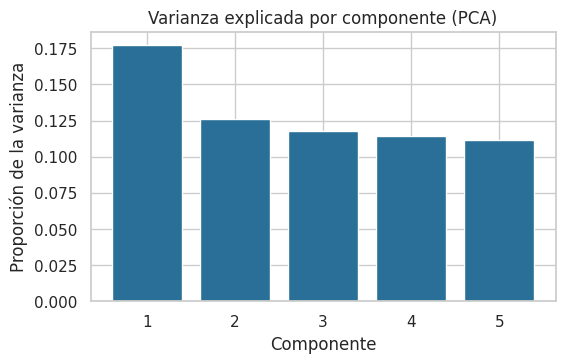

In [ ]:
pca = PCA(n_components=5, random_state=SEMILLA).fit(num_train)
plt.figure(figsize=(6, 3.5))
plt.bar(range(1, 6), pca.explained_variance_ratio_, color="#2a6f97")
plt.title("Varianza explicada por componente (PCA)")
plt.xlabel("Componente")
plt.ylabel("Proporción de la varianza")
plt.show()

In [ ]:
modelo2 = clone(modelo).fit(X_train, y_train)
son_iguales = bool(np.array_equal(modelo.predict(X_test), modelo2.predict(X_test)))
assert son_iguales, "Las predicciones deberían coincidir: comprueba que fijas la semilla y ajustas con los mismos datos"
assert modelo2 is not modelo, "modelo2 debe ser una instancia nueva (usa clone)"

In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     TimeSeriesSplit, GridSearchCV)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_absolute_error, mean_squared_error, r2_score)

SEMILLA = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["mes_llegada"] = df["fecha_llegada"].dt.month
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "mes_llegada"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]


def hacer_preprocesado(num=columnas_num, cat=columnas_cat):
    """Receta estándar: imputar + escalar (num) e imputar + one-hot (cat)."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])


X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
print("Tasa de cancelación:", y.mean().round(3))

Tasa de cancelación: 0.459


In [ ]:
tonto = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Exactitud del baseline:", round(tonto.score(X_test, y_test), 3))

Exactitud del baseline: 0.541


In [ ]:
logistica = Pipeline([
    ("prep", hacer_preprocesado()),
    ("clf", LogisticRegression(max_iter=1000)),
]).fit(X_train, y_train)
acc_logistica = logistica.score(X_test, y_test)
mejora = acc_logistica - tonto.score(X_test, y_test)
assert acc_logistica > 0.65, "La regresión logística debería superar 0,65 de exactitud"
assert mejora > 0.05, "Debería mejorar al baseline en más de 5 puntos"

In [ ]:
pred = logistica.predict(X_test)
print(f"Exactitud {accuracy_score(y_test, pred):.3f} · Precisión {precision_score(y_test, pred):.3f} "
      f"· Recall {recall_score(y_test, pred):.3f} · F1 {f1_score(y_test, pred):.3f}")

Exactitud 0.672 · Precisión 0.653 · Recall 0.608 · F1 0.630


In [ ]:
Xp = df[["tipo_habitacion", "mes_llegada"]]
yp = df["precio_noche"]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.2, random_state=SEMILLA)
reg = Pipeline([("prep", hacer_preprocesado(num=["mes_llegada"], cat=["tipo_habitacion"])),
                ("reg", LinearRegression())]).fit(Xp_tr, yp_tr)
pred_p = reg.predict(Xp_te)
mae = mean_absolute_error(yp_te, pred_p)
rmse = mean_squared_error(yp_te, pred_p) ** 0.5
r2 = r2_score(yp_te, pred_p)
assert 5 < mae < 30, "El MAE debería estar entre 5 y 30 euros. Revisa el objetivo"
assert rmse >= mae, "El RMSE siempre es mayor o igual que el MAE"
assert 0.5 < r2 < 1, "R² debería ser alto: el tipo de habitación explica gran parte del precio"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
Xp = df[["tipo_habitacion", "mes_llegada"]]
yp = df["precio_noche"]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.2, random_state=SEMILLA)
reg = Pipeline([("prep", hacer_preprocesado(num=["mes_llegada"], cat=["tipo_habitacion"])),
                ("reg", LinearRegression())]).fit(Xp_tr, yp_tr)
pred_p = reg.predict(Xp_te)
mae = mean_absolute_error(yp_te, pred_p)
rmse = mean_squared_error(yp_te, pred_p) ** 0.5
r2 = r2_score(yp_te, pred_p)
assert 5 < mae < 30, "El MAE debería estar entre 5 y 30 euros. Revisa el objetivo"
assert rmse >= mae, "El RMSE siempre es mayor o igual que el MAE"
assert 0.5 < r2 < 1, "R² debería ser alto: el tipo de habitación explica gran parte del precio"

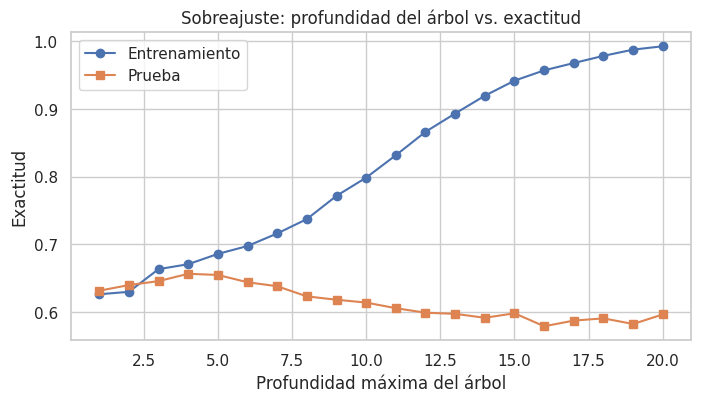

In [ ]:
prep_arbol = hacer_preprocesado()
Xtr_p = prep_arbol.fit_transform(X_train)
Xte_p = prep_arbol.transform(X_test)
profundidades = range(1, 21)
acc_tr, acc_te = [], []
for p in profundidades:
    arbol = DecisionTreeClassifier(max_depth=p, random_state=SEMILLA).fit(Xtr_p, y_train)
    acc_tr.append(arbol.score(Xtr_p, y_train))
    acc_te.append(arbol.score(Xte_p, y_test))
plt.figure(figsize=(8, 4))
plt.plot(profundidades, acc_tr, marker="o", label="Entrenamiento")
plt.plot(profundidades, acc_te, marker="s", label="Prueba")
plt.title("Sobreajuste: profundidad del árbol vs. exactitud")
plt.xlabel("Profundidad máxima del árbol")
plt.ylabel("Exactitud")
plt.legend()
plt.show()

In [ ]:
mejor_profundidad = list(profundidades)[int(np.argmax(acc_te))]
brecha_maxima = acc_tr[-1] - acc_te[-1]
assert 1 <= mejor_profundidad <= 20
assert brecha_maxima > 0.2, "Con profundidad 20 la brecha train-test debería ser grande (sobreajuste)"
print(f"Mejor profundidad en test: {mejor_profundidad} · brecha con profundidad 20: {brecha_maxima:.2f}")

Mejor profundidad en test: 4 · brecha con profundidad 20: 0.40


In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
mejor_profundidad = list(profundidades)[int(np.argmax(acc_te))]
brecha_maxima = acc_tr[-1] - acc_te[-1]
assert 1 <= mejor_profundidad <= 20
assert brecha_maxima > 0.2, "Con profundidad 20 la brecha train-test debería ser grande (sobreajuste)"
print(f"Mejor profundidad en test: {mejor_profundidad} · brecha con profundidad 20: {brecha_maxima:.2f}")

Mejor profundidad en test: 4 · brecha con profundidad 20: 0.40


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
puntuaciones = cross_val_score(logistica, X_train, y_train, cv=cv, scoring="accuracy")
print("Exactitud por fold:", puntuaciones.round(3))
print(f"Media {puntuaciones.mean():.3f} ± {puntuaciones.std():.3f}")

Exactitud por fold: [0.678 0.675 0.699 0.676 0.712]
Media 0.688 ± 0.015


In [ ]:
auc_cv = cross_val_score(logistica, X_train, y_train, cv=cv, scoring="roc_auc")
auc_medio = auc_cv.mean()
assert len(auc_cv) == 5, "Deben ser 5 puntuaciones (5 folds)"
assert 0.65 < auc_medio < 0.95, "El AUC medio debería estar entre 0,65 y 0,95"

In [ ]:
rng = np.random.default_rng(SEMILLA)
X_fuga = X.copy()
X_fuga["reembolso_emitido"] = np.where(y == 1, rng.choice([1, 1, 1, 0], len(y)), 0)  # casi = cancelada
prep_fuga = hacer_preprocesado(num=columnas_num + ["reembolso_emitido"])
modelo_fuga = Pipeline([("prep", prep_fuga), ("clf", LogisticRegression(max_iter=1000))])
auc_fuga = cross_val_score(modelo_fuga, X_fuga, y, cv=cv, scoring="roc_auc").mean()
auc_real = cross_val_score(logistica, X, y, cv=cv, scoring="roc_auc").mean()
print(f"AUC sin la columna: {auc_real:.3f} · AUC con la columna que 'delata' el resultado: {auc_fuga:.3f}")

AUC sin la columna: 0.753 · AUC con la columna que 'delata' el resultado: 0.937


In [ ]:
candidatas = {
    "antelacion_dias": "días entre reservar y llegar (se conoce al reservar)",
    "importe_devuelto": "euros reembolsados al cliente tras cancelar",
    "tarifa": "flexible o no reembolsable (se elige al reservar)",
    "fecha_cancelacion": "fecha en que el cliente canceló (vacía si no canceló)",
    "cancelaciones_previas": "cancelaciones de reservas anteriores del cliente",
}
columnas_con_fuga = ["importe_devuelto", "fecha_cancelacion"]
assert set(columnas_con_fuga) == {"importe_devuelto", "fecha_cancelacion"}, "Piensa en qué datos solo existen DESPUÉS de cancelar"

In [ ]:
df_ord = df.sort_values("fecha_reserva").reset_index(drop=True)
corte = int(len(df_ord) * 0.8)
Xo, yo = df_ord[columnas_num + columnas_cat], df_ord["cancelada"]
mod_t = Pipeline([("prep", hacer_preprocesado()), ("clf", LogisticRegression(max_iter=1000))])
mod_t.fit(Xo.iloc[:corte], yo.iloc[:corte])
print("Fecha de corte:", df_ord.loc[corte, "fecha_reserva"].date())
print("Exactitud en el futuro (partición temporal):", round(mod_t.score(Xo.iloc[corte:], yo.iloc[corte:]), 3))

Fecha de corte: 2025-08-06
Exactitud en el futuro (partición temporal): 0.655


In [ ]:
auc_temporal = cross_val_score(mod_t, Xo, yo, cv=TimeSeriesSplit(n_splits=4), scoring="roc_auc")
assert len(auc_temporal) == 4, "Debe haber 4 puntuaciones"
assert auc_temporal.min() > 0.6, "Cada corte debería superar 0,6 de AUC"

In [ ]:
#@title 🆘 Solución de referencia (si este ejercicio se queda para casa, ejecuta esta celda para seguir; ábrela solo después de intentarlo)
auc_temporal = cross_val_score(mod_t, Xo, yo, cv=TimeSeriesSplit(n_splits=4), scoring="roc_auc")
assert len(auc_temporal) == 4, "Debe haber 4 puntuaciones"
assert auc_temporal.min() > 0.6, "Cada corte debería superar 0,6 de AUC"

In [ ]:
rejilla = {"clf__C": [0.01, 0.1, 1, 10]}
busqueda = GridSearchCV(logistica, rejilla, cv=cv, scoring="roc_auc").fit(X_train, y_train)
print("Mejor C:", busqueda.best_params_, "· AUC en validación:", round(busqueda.best_score_, 3))

Mejor C: {'clf__C': 0.1} · AUC en validación: 0.755


In [ ]:
baseline_cv = Pipeline([
    ("prep", hacer_preprocesado()),
    ("clf", DummyClassifier(strategy="prior")),
])
punt = {
    "baseline": cross_val_score(baseline_cv, X_train, y_train, cv=cv, scoring="roc_auc"),
    "logistica": cross_val_score(logistica, X_train, y_train, cv=cv, scoring="roc_auc"),
}
resultados = pd.DataFrame({
    "auc_cv_media": {k: v.mean() for k, v in punt.items()},
    "auc_cv_desv": {k: v.std() for k, v in punt.items()},
}).round(3)
conclusion = (f"Sí compensa: la regresión logística logra un AUC medio de "
              f"{resultados.loc['logistica', 'auc_cv_media']:.2f} frente a 0,50 del baseline, "
              f"con poca variación entre folds.")
assert list(resultados.index) == ["baseline", "logistica"]
assert abs(resultados.loc["baseline", "auc_cv_media"] - 0.5) < 0.01, "El baseline debería dar AUC ≈ 0,5"
assert resultados.loc["logistica", "auc_cv_media"] > 0.65
assert isinstance(conclusion, str) and len(conclusion) > 20
resultados

,auc_cv_media,auc_cv_desv
baseline,0.500,0.000
logistica,0.755,0.012
